---
title: Performance Management - A Quantum Function by Q-CTRL Fire Opal
description: Apply automated error suppression using Fire Opal Performance Management by Q-CTRL
---


{/* cspell:ignore fontsize, Mundada, Yamauchi, supersymmetric, Paterakis, Gharibyan */}

# Performance Management: A Quantum Function by Q-CTRL Fire Opal

*See the [API reference](/docs/api/functions/q-ctrl-performance-management)*

<Admonition type="note" title="Note">
   Quantum Functions are an experimental feature available only to IBM Quantum&reg; Premium Plan, Flex Plan, and On-Prem (via IBM Quantum Platform API) Plan users. They are in preview release status and subject to change.
</Admonition>

{/*
  DO NOT EDIT THIS CELL!!!
  This cell's content is generated automatically by a script. Anything you add
  here will be removed next time the notebook is run. To add new content, create
  a new cell before or after this one.
*/}

<Accordion>
<AccordionItem title="Package versions">

The code on this page was developed using the following requirements.
We recommend using these versions or newer.

```
qiskit[all]~=2.3.1
qiskit-ibm-runtime~=0.45.1
```
</AccordionItem>
</Accordion>

## Overview

Fire Opal Performance Management makes it simple for anyone to achieve meaningful results from quantum computers at scale without needing to be quantum hardware experts. When running circuits with Fire Opal Performance Management, AI-driven error suppression techniques are automatically applied, enabling the scaling of larger problems with more gates and qubits. This approach reduces the number of shots required to reach the correct answer, with no added overhead, resulting in significant savings in both compute time and cost.

Performance Management suppresses errors and increases the probability of getting the correct answer on noisy hardware. In other words, it increases the signal-to-noise ratio. The following image shows how increased accuracy enabled by Performance Management can reduce the need for additional shots in the case of a 10-qubit Quantum Fourier Transform algorithm. With only 30 shots, Q-CTRL reaches the 99% confidence threshold, whereas the default (`QiskitRuntime` Sampler, `optimization_level`=3 and `resilience_level`=1, `ibm_sherbrooke`) requires 170,000 shots. By getting the right answer faster, you save significant compute runtime.

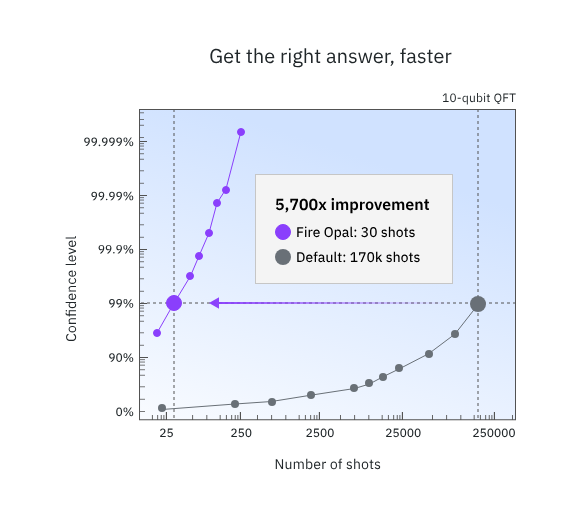

The Performance Management function can be used with any algorithm, and you can easily use it in place of the standard [IBM Quantum primitives](/docs/guides/primitives). Behind the scenes, multiple error suppression techniques work together to prevent errors from happening at runtime. All Fire Opal pipeline methods are pre-configured and algorithm-agnostic, meaning you always get the best performance out of the box.

To get access to Performance Management, [contact Q-CTRL](https://form.typeform.com/to/uOAVDnGg?typeform-source=q-ctrl.com).

## Description

Fire Opal Performance Management has two options for execution that are similar to the IBM Quantum primitives, so you can easily swap in the Q-CTRL Sampler and Estimator. The general workflow for using the Performance Management function is:
1. Define your circuit (and operators in the case of the Estimator).
2. Run the circuit.
3. Retrieve the results.

To reduce hardware noise, Fire Opal employs a range of AI-driven error suppression techniques depicted in the following image. With Fire Opal, the entire pipeline is completely automated with zero need for configuration.

Fire Opal's pipeline eliminates the need for additional overhead, such as increased quantum runtime or extra physical qubits. Note that classical processing time remains a factor (refer to the [Benchmarks](#benchmarks) section for estimates, where "Total time" reflects both classical and quantum processing). In contrast to error mitigation, which requires overhead in the form of sampling, Fire Opal's error suppression works at both the gate and pulse levels to address various sources of noise and to prevent the likelihood of an error occurring. By preventing errors, the need for expensive post-processing is eliminated.

The following image depicts the error suppression methods automated by Fire Opal Performance Management.

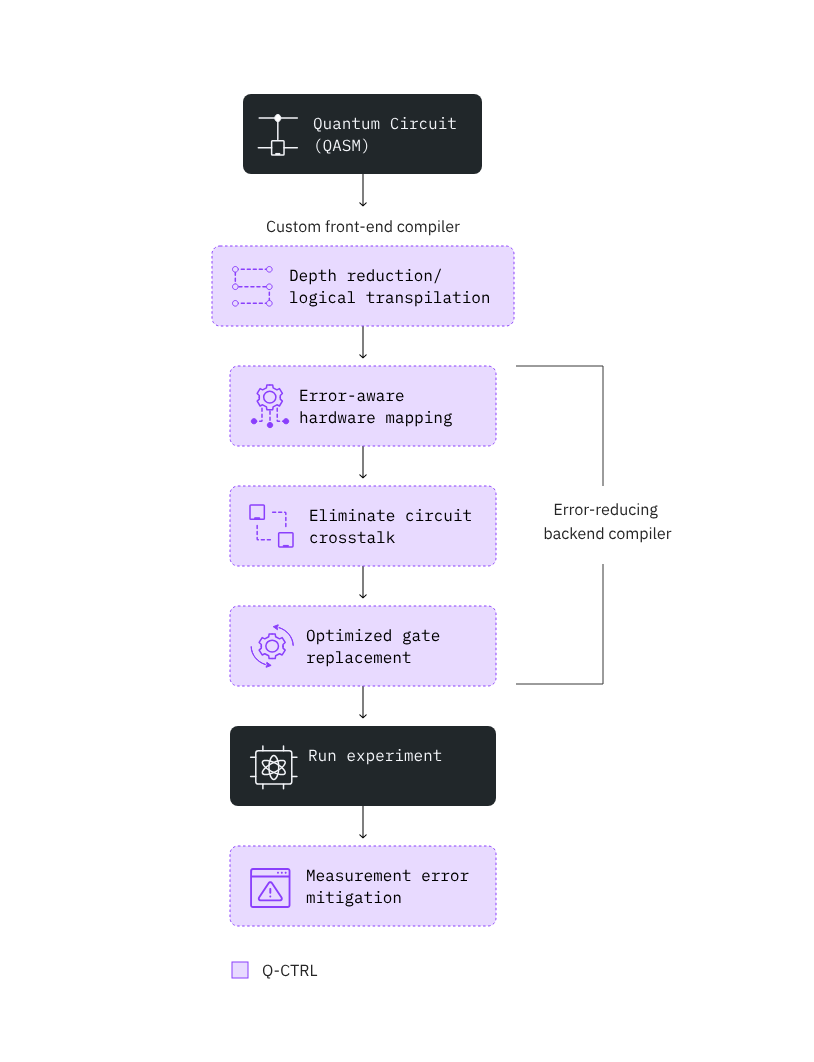

The function offers two primitives, Sampler and Estimator, and the inputs and outputs of both extend the implemented spec for [IBM Quantum V2 primitives](/docs/guides/primitive-input-output#pubs). To access results from previous runs, see [how to retrieve previous Quantum Function jobs](/docs/guides/functions-get-started#list-previously-run-qiskit-functions-jobs).

## Benchmarks

[Published algorithmic benchmarking](https://journals.aps.org/prapplied/abstract/10.1103/PhysRevApplied.20.024034) results demonstrate significant performance improvement across various algorithms, including Bernstein-Vazirani, quantum Fourier transform, Grover’s search, quantum approximate optimization algorithm, and variational quantum eigensolver. The rest of this section provides more details about types of algorithms you can run, as well as the expected performance and runtimes.

The following independent studies demonstrate how Q-CTRL's Performance Management enables algorithmic research at record-breaking scale:
- [Parametrized Energy-Efficient Quantum Kernels for Network Service Fault Diagnosis](https://arxiv.org/abs/2405.09724v1) - up to 50-qubit quantum kernel learning
- [Tensor-based quantum phase difference estimation for large-scale demonstration](https://arxiv.org/abs/2408.04946) - up to 33-qubit quantum phase estimation
- [Hierarchical Learning for Quantum ML: Novel Training Technique for Large-Scale Variational Quantum Circuits](https://arxiv.org/abs/2311.12929) - up to 21-qubit quantum data loading

The following table provides a rough guide on accuracy and runtimes from prior benchmarking runs on `ibm_fez`. Performance on other devices may vary. The usage time is based on an assumption of 10,000 shots per circuit. The "Number of qubits" indicated is not a hard limitation but represents rough thresholds where you can expect extremely consistent solution accuracy. Larger problem sizes have been successfully solved, and testing beyond these limits is encouraged.


| Example    | Number of qubits | Accuracy | Measure of accuracy | Total time (s) | Runtime usage (s) | Primitive (Mode) |
| ---------  | ---------------- | -------------------------- | -------- | ---------- | ------------- |------------- |
| Bernstein–Vazirani  |  50Q    | 100%  | Success Rate (Percentage of runs where the correct answer is the highest count bitstring)     | 10    | 8         | Sampler |
| Quantum Fourier Transform | 30Q              | 100% | Success Rate (Percentage of runs where the correct answer is the highest count bitstring)      | 10    | 8        | Sampler |
| Quantum Phase Estimation  | 30Q   | 99.9998%  | Accuracy of the angle found: `1- abs(real_angle - angle_found)/pi`  | 10  | 8  | Sampler |
| Quantum simulation: Ising model (15 steps) | 20Q  | 99.775%   |  $A$ (defined below)  |  60 (per step)  | 15 (per step)   | Estimator |
| Quantum simulation 2: molecular dynamics (20 time points) | 34Q  |  96.78%  |  $A_{mean}$ (defined below)   | 10 (per time point)    | 6 (per time point)  | Estimator |

Defining the accuracy of the measurement of an expectation value - the metric $A$ is defined as follows:
$$
A = 1 - \frac{|\epsilon^{ideal} - \epsilon^{meas}|}{\epsilon^{ideal}_{max} - \epsilon^{ideal}_{min}},
$$
where $ \epsilon^{ideal} $ = ideal expectation value,  $ \epsilon^{meas} $ = measured expectation value, $\epsilon^{ideal}_{max} $ = ideal maximum value, and $\epsilon^{ideal}_{min}$ = ideal minimum value. $A_{mean}$ is simply the average of the value of $A$ across multiple measurements.

This metric is used because it is invariant to global shifts and scaling in the range of attainable values. In other words, regardless of whether you shift the range of possible expectation values higher or lower or increase the spread, the value of $A$ should remain consistent.

## Get started

Fire Opal Performance Management uses Qiskit v`2.0.0`, which is the recommended version. Supported versions are Qiskit >=v`2.0.0`.
Authenticate using your [IBM Quantum Platform API key](http://quantum.cloud.ibm.com/), and select the Quantum Function as follows. (This snippet assumes you've already [saved your account](/docs/guides/functions-get-started#install-qiskit-functions-catalog-client) to your local environment.)

In [1]:
# This cell is hidden from users. It hides the "...You have imported samplomatic..." warning.
import warnings

warnings.filterwarnings("ignore", message=".*You have imported samplomatic*")

In [2]:
from qiskit_ibm_catalog import QiskitFunctionsCatalog

catalog = QiskitFunctionsCatalog(channel="ibm_quantum_platform")

In [3]:
# Access Function
perf_mgmt = catalog.load("q-ctrl/performance-management")

<Admonition type="note" title="Does this function support all IBM backends?">
If you want to use a backend that this function does not currently support, [reach out to Q-CTRL](https://form.typeform.com/to/iuujEAEI?typeform-source=q-ctrl.com) to add support.
</Admonition>

## Workload size

When submitting a workload, set `function_size` to `"S"`, `"M"`, or `"L"` to select the appropriate compute profile. The same sizing rules apply to both Sampler and Estimator.

For Performance Management, the workload size depends on the number of active physical qubits and the two-qubit gate depth after the circuit is mapped and routed to the selected backend. The sizing calculation uses mapping and routing equivalent to Qiskit's `optimization_level=0`.

Active qubits are the physical qubits used by circuit operations, excluding barriers. The two-qubit gate depth counts only two-qubit operations, also excluding barriers. Routing can increase both values, so the required size depends on the selected backend as well as the input circuit.

| Workload size | Active qubits | Two-qubit gate depth | Rule |
| --- | --- | --- | --- |
| Small (`"S"`) | ≤ 40 | ≤ 40 | Both metrics must satisfy the Small limits. |
| Medium (`"M"`) | ≤ 100 | ≤ 100 | At least one metric exceeds its Small limit, but both remain within the Medium limits. |
| Large (`"L"`) | > 100 | > 100 | Either active qubits or two-qubit gate depth exceeds its Medium limit. |

If you submit multiple PUBs, select the largest size required by any circuit in the workload. For example, a mapped circuit with 30 active qubits and a two-qubit gate depth of 60 requires `"M"`.

If the selected size is smaller than the workload requires, execution stops with a `ServerlessError` (IBM error code `4600`). Resubmit the workload with the required size. Selecting a larger size than needed produces a warning (IBM code `4601`), but execution continues.


Use the following helper to estimate the workload size for the PUB tuples. It maps and routes each circuit to the selected backend with `optimization_level=0`, then checks the active qubits and two-qubit gate depth, excluding barriers. For multiple PUBs, it returns the largest required size.

In [4]:
"""
Size calculator for a circuit function.

**Ship this file as it is.** A size has to mean the same thing across every circuit
function, so there is nothing here for a vendor to fill in: copy the file into your image
and call ``validate_size`` from your entrypoint. If your function cannot be sized by
this file, say so rather than editing the sizing -- the limits and the measurement are
IBM's, and a local change to either makes your sizes incomparable with everyone else's.

Input:  ``calculate_function_size(circuit, backend, **kwargs)`` -- the circuit and the backend it
        will run on are both required, and the other function inputs arrive as
        ``**kwargs``. The backend is needed because the size depends on its coupling map,
        so pass it by keyword through ``validate_size``:
        ``validate_size("S", circuit, backend=backend)``. A list of PUBs is accepted in
        place of a single circuit, and is sized as the largest of its PUBs.
Output: ``"S"``, ``"M"`` or ``"L"``, from the number of active qubits and the
        two-qubit-gate depth after mapping the circuit onto ``backend``.

Call ``validate_size`` **once** per job, on everything the job will submit -- the
whole PUB list, not one PUB at a time. A job runs at a single size, so it has to be sized
for its heaviest PUB; calling per PUB would also emit one oversize event per PUB.

The mapping is done by ``_pass_manager``, which spells out the passes rather than calling
``generate_preset_pass_manager(optimization_level=0)``, so that a future change to the
preset recipe cannot silently move every vendor's calculates.

Routing is seeded, because routing is stochastic and ``validate_size``
re-calculates: with an unseeded pass manager the same circuit can be sized differently on
consecutive calls, so a job could be rejected on a size an identical earlier call accepted.

``QuantumCircuit.depth(filter_function)`` counts only the instructions for which
``filter_function`` returns True, so a two-qubit filter gives the two-qubit-gate depth.
https://quantum.cloud.ibm.com/docs/api/qiskit/qiskit.circuit.QuantumCircuit#depth

Depends only on Qiskit and ``qiskit-serverless``, so the same file runs in your image and
in a user's notebook.
"""
from __future__ import annotations

from collections.abc import Iterable
from typing import Any, Literal

from qiskit import QuantumCircuit
from qiskit.circuit import Barrier
from qiskit.circuit.equivalence_library import SessionEquivalenceLibrary
from qiskit.transpiler import PassManager
from qiskit.transpiler.passes import (
    ApplyLayout,
    BarrierBeforeFinalMeasurements,
    BasisTranslator,
    EnlargeWithAncilla,
    FilterOpNodes,
    FullAncillaAllocation,
    HighLevelSynthesis,
    SabreSwap,
    TrivialLayout,
    UnitarySynthesis,
)

from qiskit_serverless import (
    ServerlessError,
    get_function_size,
    get_logger,
    send_error,
)

Size = Literal["S", "M", "L"]
_ORDER = {"S": 0, "M": 1, "L": 2}

# Error codes assigned by IBM; see the IBM Quantum error registry.
SIZE_TOO_SMALL_ERROR_CODE = "4600"
SIZE_TOO_LARGE_ERROR_CODE = "4601"

# Limits are provided by IBM
_SMALL_QUBITS, _SMALL_DEPTH_2Q = 40, 40
_MEDIUM_QUBITS, _MEDIUM_DEPTH_2Q = 100, 100

# Any fixed value works; what matters is that it does not change between calls.
_SEED_TRANSPILER = 42

# Added by BarrierBeforeFinalMeasurements so routing cannot move gates past a measurement,
# then removed again once routing is done.
_PROTECTION_BARRIER = "qiskit.transpiler.internal.routing.protection.barrier"


def calculate_function_size(circuit: QuantumCircuit | Iterable[Any], backend, **kwargs: Any) -> Size:
    """Return the size ("S", "M" or "L") required to run the function.

    ``circuit`` is either one ``QuantumCircuit`` or a list of PUBs. For a list, every PUB
    circuit is sized on its own and the largest size wins: the job runs on one size, so it
    has to be the size the heaviest PUB needs.
    """
    circuits = pub_circuits(circuit)
    if not circuits:
        raise ValueError("No circuit to size: pass a QuantumCircuit or a non-empty list of PUBs.")
    return max(
        (_calculate_circuit_size(qc, backend, **kwargs) for qc in circuits),
        key=_ORDER.__getitem__,
    )


def _calculate_circuit_size(circuit: QuantumCircuit, backend, **kwargs: Any) -> Size:
    """Return the size required to run a single circuit."""
    metrics = _measure(circuit, backend, **kwargs)
    if _is_small(metrics):
        return "S"
    if _is_medium(metrics):
        return "M"
    return "L"


def pub_circuits(problem: Any) -> list[QuantumCircuit]:
    """Return the circuits in ``problem``: one circuit, or one per PUB in a list of PUBs.

    A PUB may be a bare circuit, a tuple/list whose first item is the circuit, or a coerced
    ``SamplerPub`` / ``EstimatorPub`` (which carries a ``.circuit`` attribute).
    """
    if isinstance(problem, QuantumCircuit):
        return [problem]
    circuits: list[QuantumCircuit] = []
    for index, pub in enumerate(problem):
        if isinstance(pub, QuantumCircuit):
            circuit = pub
        elif isinstance(getattr(pub, "circuit", None), QuantumCircuit):
            circuit = pub.circuit
        elif isinstance(pub, (tuple, list)) and pub and isinstance(pub[0], QuantumCircuit):
            circuit = pub[0]
        else:
            raise ValueError(f"PUB #{index} has no QuantumCircuit to size.")
        circuits.append(circuit)
    return circuits


def _pass_manager(target) -> PassManager:
    """Return the pass manager used to map a circuit onto ``target``.

    This spells out the passes that ``generate_preset_pass_manager(optimization_level=0)``
    assembles today, so that a future change to the level-0 recipe cannot silently move
    every vendor's size calculates. It is the pass list that is pinned, not the passes: a
    new Qiskit release can still change what ``SabreSwap`` or ``BasisTranslator`` does.

    Stages, mirroring the preset: unroll anything wider than two qubits, lay the circuit
    out trivially and pad it to the backend width, route it, then translate to the
    backend basis. Level 0 runs no optimization stage.
    """
    basis = list(target.operation_names)
    library = SessionEquivalenceLibrary
    return PassManager(
        [
            UnitarySynthesis(basis, approximation_degree=1.0, min_qubits=3, target=target),
            HighLevelSynthesis(
                target=target,
                equivalence_library=library,
                basis_gates=basis,
                min_qubits=3,
            ),
            BasisTranslator(library, basis, target=target, min_qubits=3),
            TrivialLayout(target),
            FullAncillaAllocation(target),
            EnlargeWithAncilla(),
            ApplyLayout(),
            BarrierBeforeFinalMeasurements(label=_PROTECTION_BARRIER),
            SabreSwap(target, heuristic="basic", seed=_SEED_TRANSPILER, trials=5),
            FilterOpNodes(lambda node: node.label != _PROTECTION_BARRIER),
            UnitarySynthesis(basis, approximation_degree=1.0, target=target),
            HighLevelSynthesis(
                target=target,
                equivalence_library=library,
                basis_gates=basis,
                use_qubit_indices=True,
            ),
            BasisTranslator(library, basis, target=target),
        ]
    )


def _count(isa: QuantumCircuit) -> dict:
    """Return the number of active qubits and the two-qubit-gate depth of a mapped circuit.

    ``isa.num_qubits`` would be the width of the whole backend, so only the qubits that
    carry an operation are counted.
    """
    active = {q for instr in isa.data if not isinstance(instr.operation, Barrier) for q in instr.qubits}
    return {
        "num_qubits": len(active),
        "depth_2q": isa.depth(
            filter_function=lambda instr: len(instr.qubits) == 2 and not isinstance(instr.operation, Barrier)
        ),
    }


def _measure(circuit: QuantumCircuit, backend, **kwargs: Any) -> dict:  # pylint: disable=unused-argument
    """Map ``circuit`` onto ``backend`` and return its metrics."""
    return _count(_pass_manager(backend.target).run(circuit))


def _is_small(metrics: dict) -> bool:
    """Determine if the metrics fit T-size 'S'."""
    return metrics["num_qubits"] <= _SMALL_QUBITS and metrics["depth_2q"] <= _SMALL_DEPTH_2Q


def _is_medium(metrics: dict) -> bool:
    """Determine if the metrics fit T-size 'M'."""
    return metrics["num_qubits"] <= _MEDIUM_QUBITS and metrics["depth_2q"] <= _MEDIUM_DEPTH_2Q


def validate_size(
    circuit: QuantumCircuit | Iterable[Any], backend, **kwargs: Any
) -> None:
    """Call once at the start of your function, on everything the job will submit.

    Compare the size the job was given with the calculated size and log both. Raise if
    the given size is smaller than the calculation; report a non-fatal event and continue
    if it is larger. Pass the whole PUB list rather than calling this per PUB: the job
    runs at one size, and a per-PUB call would emit one oversize event per PUB."""
    logger = get_logger()
    provided = get_function_size()
    if not provided:
        # Empty on non-Fleets (Ray) jobs, where sizes do not apply.
        logger.warning("No function size was given to this job; skipping the size check.")
        return
    provided = provided.upper()
    expected = calculate_function_size(circuit, backend, **kwargs)
    logger.info("Function size given: '%s'; calculated size: '%s'.", provided, expected)
    if _ORDER[provided] < _ORDER[expected]:
        logger.error("Size '%s' is too small; the calculated size is '%s'.", provided, expected)
        raise ServerlessError(
            code=SIZE_TOO_SMALL_ERROR_CODE,
            message=f"Size '{provided}' is too small for this problem; expected '{expected}' or larger.",
        )
    if _ORDER[provided] > _ORDER[expected]:
        logger.warning(
            "Size '%s' is larger than this problem needs; the calculated size is '%s'.",
            provided,
            expected,
        )
        send_error(
            code=SIZE_TOO_LARGE_ERROR_CODE,
            message="The specified function size is larger than this job requires.",
            exception="FunctionSizeTooLarge",
            args={
                "provided_size": provided,
                "calculated_size": expected,
                "solution": (
                    "No action is required and the job completed normally. To reduce "
                    "cost, use a smaller function size for jobs of this kind."
                ),
            },
        )


## Estimator primitive

### Estimator example

Use Fire Opal Performance Management's Estimator primitive to determine the expectation value of a single circuit-observable pair.

In addition to the `qiskit-ibm-catalog` and `qiskit` packages, you will also use the `numpy` package to run this example. You can install this package by uncommenting the following cell if you are running this example in a notebook using the IPython kernel.

In [5]:
# %pip install numpy

**1. Create the circuit**

As an example, generate a random Hermitian operator and an observable to input to the Performance Management function.

In [5]:
import numpy as np
from qiskit.circuit.library import iqp
from qiskit.quantum_info import random_hermitian, SparsePauliOp

n_qubits = 37

# Generate a random circuit
mat = np.real(random_hermitian(n_qubits, seed=1234))
circuit = iqp(mat)
circuit.measure_all()

# Define observables as a string
observable = SparsePauliOp("Z" * n_qubits)

In [6]:
# Create PUB tuple
estimator_pubs = [(circuit, observable)]

**2. Run the circuit**

Calculate the workload size for `estimator_pubs` on the selected backend, then pass the returned value to `perf_mgmt.run` through `function_size`. You can also specify the number of shots.

In [7]:
# This cell is hidden from users
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService()
backend_name = service.least_busy().name

In [8]:
backend = catalog.backend(backend_name)
estimator_size = calculate_function_size(estimator_pubs, backend)
print(f"Workload size: {estimator_size}")

Workload size: M


In [10]:
# Run the circuit using Estimator
qctrl_estimator_job = perf_mgmt.run(
    primitive="estimator",
    pubs=estimator_pubs,
    backend_name=backend_name,
    function_size=estimator_size
)

You can use the familiar [Qiskit Serverless APIs](/docs/guides/serverless) to check your Quantum Function workload's status:

In [11]:
qctrl_estimator_job.status()

'DONE'

**3. Retrieve the result**

In [12]:
# Retrieve the counts from the result list
result = qctrl_estimator_job.result()

The results have the same format as an [Estimator result](/docs/guides/estimator-input-output):

In [13]:
import numpy

result_str = str(result)

with numpy.printoptions(threshold=200):
    print(
        f"The result of the submitted job had {len(result)} PUB "
        f"and has a value:\n {result[0]}\n"
    )

print("The associated PubResult of this job has the following DataBins:")
print(f"{result[0].data}\n")

print(f"And this DataBin has attributes: {result[0].data.keys()}")

print("The expectation values measured from this PUB are:")
print(f"{result[0].data.evs}")

The result of the submitted job had 1 PUB and has a value:
 PubResult(data=DataBin(evs=np.ndarray(<shape=(1,), dtype=float64>), stds=np.ndarray(<shape=(1,), dtype=float64>)), metadata={'precision': None})

The associated PubResult of this job has the following DataBins:
DataBin(evs=np.ndarray(<shape=(1,), dtype=float64>), stds=np.ndarray(<shape=(1,), dtype=float64>))

And this DataBin has attributes: dict_keys(['evs', 'stds'])
The expectation values measured from this PUB are:
[0.00252317]


## Sampler primitive

### Sampler example

Use Fire Opal Performance Management's Sampler primitive to run a Bernstein–Vazirani circuit. This algorithm, used to find a hidden string from the outputs of a black box function, is a common benchmarking algorithm because there is a single correct answer.

**1. Create the circuit**

Define the correct answer to the algorithm, the hidden bitstring, and the Bernstein–Vazirani circuit. You can adjust the width of the circuit by simply changing the `circuit_width`.

In [33]:
import qiskit

circuit_width = 14
hidden_bitstring = "1" * circuit_width

# Create circuit, reserving one qubit for BV oracle
bv_circuit = qiskit.QuantumCircuit(circuit_width + 1, circuit_width)
bv_circuit.x(circuit_width)
bv_circuit.h(range(circuit_width + 1))
for input_qubit, bit in enumerate(reversed(hidden_bitstring)):
    if bit == "1":
        bv_circuit.cx(input_qubit, circuit_width)
bv_circuit.barrier()
bv_circuit.h(range(circuit_width + 1))
bv_circuit.barrier()
for input_qubit in range(circuit_width):
    bv_circuit.measure(input_qubit, input_qubit)

# Create PUB tuple
sampler_pubs = [(bv_circuit,)]

**2. Run the circuit**

Calculate the workload size for `sampler_pubs` on the selected backend, then pass the returned value to `perf_mgmt.run` through `function_size`. You can also specify the number of shots.

In [34]:
# Calculate the workload size for the selected backend
backend = catalog.backend(backend_name)
sampler_size = calculate_function_size(sampler_pubs, backend)
print(f"Workload size: {sampler_size}")

Workload size: M


In [35]:
# Run the circuit using Sampler
qctrl_sampler_job = perf_mgmt.run(
    primitive="sampler",
    pubs=sampler_pubs,
    backend_name=backend_name,
    function_size=sampler_size
)

Check your Quantum Function workload's [status](/docs/guides/functions-get-started#check-job-status) or return [results](/docs/guides/functions-get-started#retrieve-results) as follows:

In [36]:
# Print the ID so you can use it later, if necessary
print(qctrl_sampler_job.job_id)

qctrl_sampler_job.status()

d35c9efc-1542-461d-ae19-5485cab3fd80


'DONE'

**3. Retrieve the result**

In [37]:
# Retrieve the job results
sampler_result = qctrl_sampler_job.result()

In [38]:
# Get results for the first (and only) PUB
pub_result = sampler_result[0]
counts = pub_result.data.c.get_counts()

print("Counts for the meas output register (limited to 30 results):")
for i, (bitstring, count) in enumerate(counts.items()):
    if i >= 50:
        print(f"  ... ({len(counts) - 30} more items)")
        break
    print(f"  {bitstring}: {count}")

Counts for the meas output register (limited to 30 results):
  11111111111111: 2715
  11111101111111: 134
  11111111110111: 102
  11111011111111: 73
  11111111111110: 66
  00000000000111: 60
  11111111111101: 59
  11111110111111: 50
  11110111111111: 48
  11111111101111: 47
  11111111011111: 34
  11011111111111: 30
  10111111111111: 27
  00111111111111: 24
  00011111111111: 23
  01111111111111: 22
  00000000010111: 20
  00000001110111: 19
  00000000000001: 18
  11111110011111: 18
  00000011111111: 16
  11101111111111: 15
  00000001111111: 14
  00001011111111: 11
  00000000111111: 11
  00001111111111: 10
  00000000000010: 9
  00000000001111: 9
  00000000000011: 8
  01011111111111: 8
  00000011110111: 8
  10011111111111: 7
  00000000011111: 7
  00000000000000: 7
  11111110000111: 6
  11111011110111: 5
  11111001111111: 5
  01111011111111: 5
  00000010000111: 5
  11111111010111: 4
  00000111111111: 4
  00111101111111: 4
  11111110010111: 4
  11010111111111: 4
  11111110110111: 4
  0111111

**3. Plot the top bitstrings**

Plot the bitstring with the highest counts to see if the hidden bitstring was the mode.

In [39]:
import matplotlib.pyplot as plt


def plot_top_bitstrings(counts_dict, hidden_bitstring=None):
    # Sort and take the top 100 bitstrings
    top_100 = sorted(counts_dict.items(), key=lambda x: x[1], reverse=True)[
        :100
    ]
    if not top_100:
        print("No bitstrings found in the input dictionary.")
        return

    # Unzip the bitstrings and their counts
    bitstrings, counts = zip(*top_100)

    # Assign colors: purple if the bitstring matches hidden_bitstring,
    # otherwise gray
    colors = [
        "#680CE9" if bit == hidden_bitstring else "gray" for bit in bitstrings
    ]

    # Create the bar plot
    plt.figure(figsize=(15, 8))
    plt.bar(
        range(len(bitstrings)), counts, tick_label=bitstrings, color=colors
    )

    # Rotate the bitstrings for better readability
    plt.xticks(rotation=90, fontsize=8)
    plt.xlabel("Bitstrings")
    plt.ylabel("Counts")
    plt.title("Top 100 Bitstrings by Counts")

    # Show the plot
    plt.tight_layout()
    plt.show()

The hidden bitstring is highlighted in purple, and it should be the bitstring with the highest number of counts.

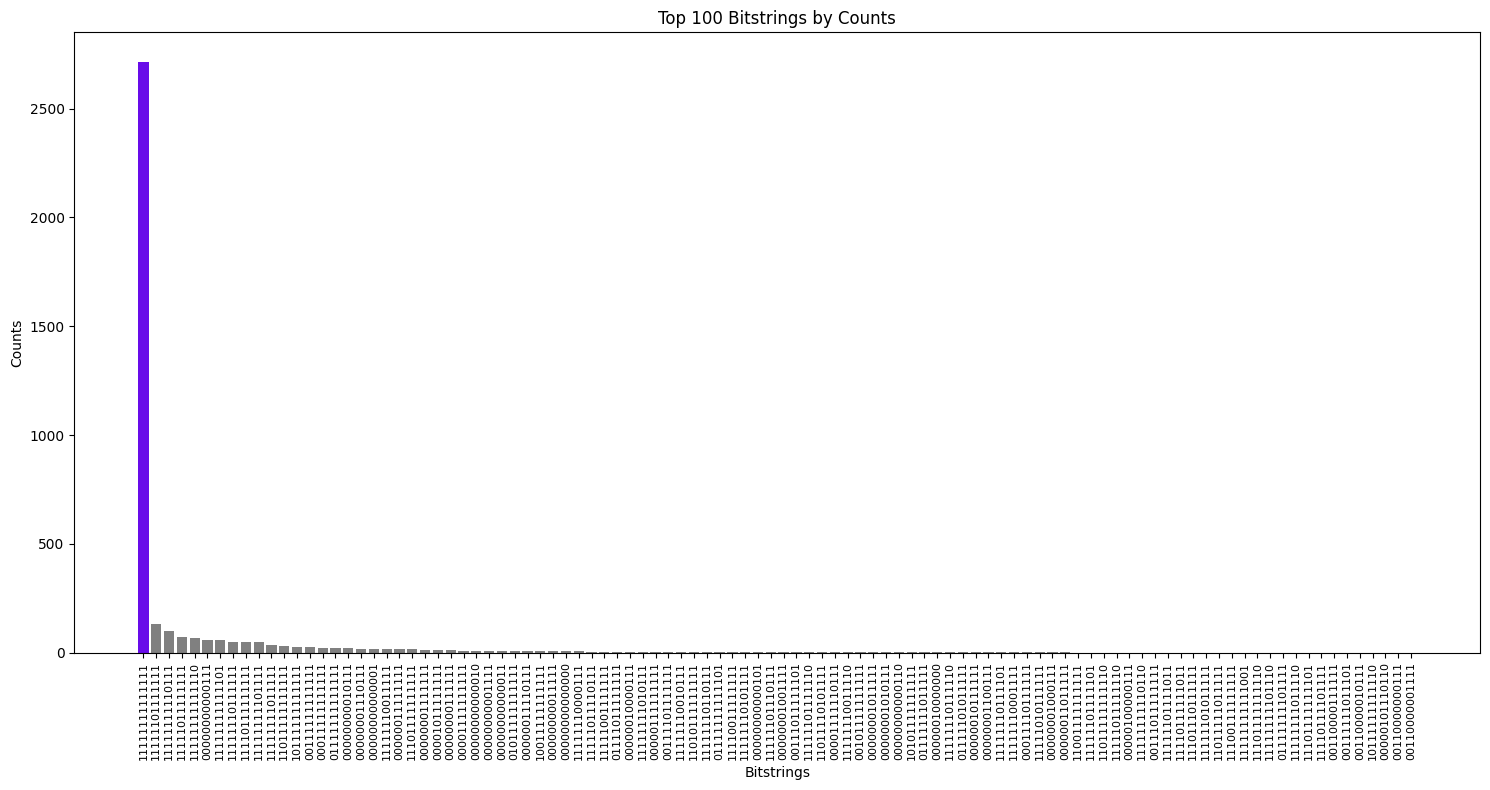

In [40]:
plot_top_bitstrings(counts, hidden_bitstring)

## Changelog

- 2026-02-20: Deprecation Notice - the `provider_job_ids` metadata field will be deprecated in 30 days in version 0.13.0. Users can access the job ID through `job_id()` method of the runtime service.
- 2026-02-11: We now have support for `ibm_miami`, and added execution metadata to the `PubResult`.

## Get support

For any questions or issues, [contact Q-CTRL](https://form.typeform.com/to/iuujEAEI).

## Next steps

<Admonition type="tip" title="Recommendations">

- Request access to [Q-CTRL Performance Management](https://quantum.cloud.ibm.com/functions?id=q-ctrl-performance-management).
- Visit the [API reference](/docs/api/functions/q-ctrl-performance-management) for this Quantum Function.
- Try the [Transverse-Field Ising Model with Q-CTRL's Performance Management](/docs/tutorials/transverse-field-ising-model) tutorial.
- Try the [Quantum Phase Estimation with Q-CTRL's Quantum Functions](/docs/tutorials/quantum-phase-estimation-qctrl) tutorial
- Review [Mundada P. S., et al. (2023). Experimental Benchmarking of an Automated Deterministic Error-Suppression Workflow for Quantum Algorithms. Physical Review Applied, 20, 2](https://quantum-journal.org/papers/q-2023-07-25-1067/).
- Review [Kanno, S., et al. (2025). Tensor-based quantum phase difference estimation for large-scale demonstration. arXiv preprint arXiv:2408.04946](https://arxiv.org/abs/2408.04946).
- Review [SoftBank Corp, Demonstration Experiment of a Communication Service Fault Diagnosis System Using Quantum Machine Learning (blog), 30 August, 2024](https://www.softbank.jp/en/corp/technology/research/topics/102/).
- Review [Yamauchi, H., et al. (2024). Parametrized Energy-Efficient Quantum Kernels for Network Service Fault Diagnosis. arXiv preprint arXiv:2405.09724v1](https://arxiv.org/abs/2405.09724v1).
- Review [Yamauchi, H., et al. (2025). Quantum spectroscopy of topological dynamics via a supersymmetric Hamiltonian. arXiv preprint arXiv:2511.23169v1](https://arxiv.org/abs/2511.23169v1).
- Review [Wang, Y., et al. (2025).  Δ-Motif: Subgraph Isomorphism at Scale via Data-Centric Parallelism. arXiv preprint arXiv:2508.21287](https://arxiv.org/abs/2508.21287).
- Review [Paterakis, N. G., et al. (2025).  Quantum Computing in the Computational Landscape of Power Electronics: Vision and Reality. arXiv preprint arXiv:2507.02577](https://arxiv.org/abs/2507.02577).
- Review [Gharibyan, H., et al. (2023).  Hierarchical Learning for Quantum ML: Novel Training Technique for Large-Scale Variational Quantum Circuits. arXiv preprint arXiv:2311.12929](https://arxiv.org/abs/2311.12929).
- Review the [Mitsubishi Chemical Corp case study](https://q-ctrl.com/case-study/unlocking-new-performance-capability-in-quantum-chemistry).
- Review the [Redacted bank case study](https://q-ctrl.com/case-study/reducing-quantum-compute-costs-2-500x-with-fire-opal).
- Review the [BlueQubit case study](https://q-ctrl.com/case-study/enabling-data-loading-for-quantum-machine-learning-with-fire-opal).


</Admonition>